In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [2]:
df=pd.read_csv("Mall_Customers.csv")

In [3]:
df['Genre']=LabelEncoder().fit_transform(df['Genre'])
df=df.drop(['CustomerID'],axis=1)
x=df[['Annual Income (k$)','Spending Score (1-100)']]

In [4]:
km=KMeans(n_clusters=5,random_state=42,n_init=10)
df['KMeans']=km.fit_predict(x)
hc=AgglomerativeClustering(n_clusters=5,linkage='ward')
df['Heirarchial']=hc.fit_predict(x)

In [5]:
print("kmeans silhoutte score: ",silhouette_score(x,df['KMeans']))
print("Heirarchial silhoutte score: ",silhouette_score(x,df['Heirarchial']))

kmeans silhoutte score:  0.553931997444648
Heirarchial silhoutte score:  0.5529945955148897


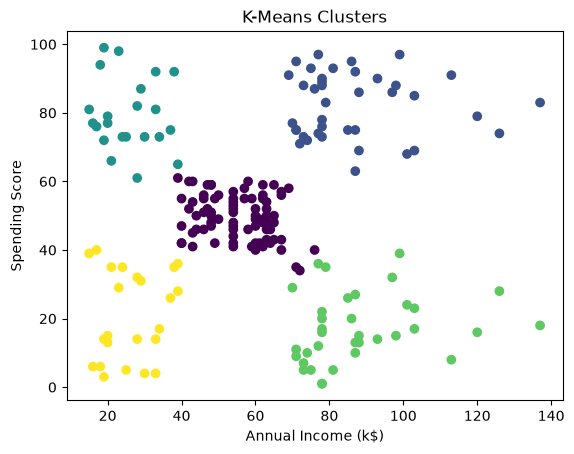

In [6]:
plt.scatter(x.iloc[:, 0], x.iloc[:, 1], c=df['KMeans'], cmap='viridis')
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("K-Means Clusters")
plt.show()